# Module 5 (cont.) & 8 — Personas, Recommendations and Prescriptive Analytics
ML Engineer (evaluation) + business analyst roles.

1. Segment profiles: behaviour, outcomes, KPIs, context mix (incl. a fairness check)
2. What distinguishes each segment (standardised differences) and persona cards
3. Weekly engagement time series per persona (Lecture 8.1)
4. **Early warning** — can a learner's segment be predicted from the first 4 weeks? (classification, Lecture 10)
5. Pedagogical and support recommendations per persona
6. **Decision analysis** — expected value of intervening per segment (Lecture 2)
7. **Optimisation** — LP allocation of a support budget and tutor capacity (Lecture 3.2) with sensitivity analysis

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src")) if (Path.cwd().parent / "src").exists() else sys.path.insert(0, "src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score
from edtech import config as C, business as B, utils as U, viz as V
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 120)

seg = pd.read_parquet(C.PROCESSED / "learner_segments.parquet")
model = joblib.load(C.MODELS / "segmentation_model.joblib")
SEL = model.features()
order = seg.groupby("segment_id").persona.first().sort_index()
PERSONAS = list(order.values)
colors = [V.PERSONA_COLORS[p] for p in PERSONAS]
print(order.to_dict())

{'S0': 'Non-starters', 'S1': 'Consistent Achievers', 'S2': 'Last-minute Crammers', 'S3': 'At-risk Disengaged'}


## 1. Segment profiles

In [2]:
prof_cols = SEL + ["logins_per_week", "submission_rate", "on_time_rate_scheduled", "median_hours_before_deadline",
                   "days_to_first_login", "mobile_share", "mean_session_minutes", "total_clicks", "engagement_score"]
prof = seg.groupby("persona")[prof_cols].median().reindex(PERSONAS).T
size = seg.persona.value_counts().reindex(PERSONAS)
outcome = pd.crosstab(seg.persona, seg.final_result, normalize="index").reindex(PERSONAS)
kpi = pd.DataFrame({"enrollments": size, "share": (size / len(seg)).round(3),
                    "median_engagement_score": seg.groupby("persona").engagement_score.median().reindex(PERSONAS),
                    "pass_rate": seg.groupby("persona").is_pass.mean().reindex(PERSONAS),
                    "distinction_rate": outcome["Distinction"], "withdrawal_rate": outcome["Withdrawn"],
                    "at_risk_rate": seg.groupby("persona").at_risk_outcome.mean().reindex(PERSONAS)}).round(3)
U.save_table(prof.round(3).reset_index(names="feature"), "m6_profile_medians"); U.save_table(kpi.reset_index(names="persona"), "m6_segment_kpis")
kpi

,enrollments,share,median_engagement_score,pass_rate,distinction_rate,withdrawal_rate,at_risk_rate
persona,,,,,,,
Non-starters,4093,0.126,5.390,0.001,0.000,0.885,0.999
Consistent Achievers,10468,0.321,83.095,0.896,0.225,0.030,0.104
Last-minute Crammers,11222,0.344,56.700,0.533,0.060,0.160,0.467
At-risk Disengaged,6810,0.209,28.320,0.003,0.000,0.650,0.997


In [3]:
prof.round(2)

persona,Non-starters,Consistent Achievers,Last-minute Crammers,At-risk Disengaged
recency_fraction,1.00,0.03,0.10,0.84
active_day_fraction,0.00,0.40,0.14,0.03
clicks_per_active_day,0.00,20.31,14.97,14.23
weekly_cv_active_span,0.00,1.01,1.61,0.91
deadline_click_ratio,0.00,1.51,3.42,0.72
avg_score_scheduled,0.00,80.15,57.61,5.17
last_minute_submission_share,0.00,0.08,0.25,0.00
video_completion_rate,0.00,0.76,0.55,0.53
forum_posts_per_week,0.00,0.23,0.00,0.00
night_login_share,0.00,0.14,0.23,0.11


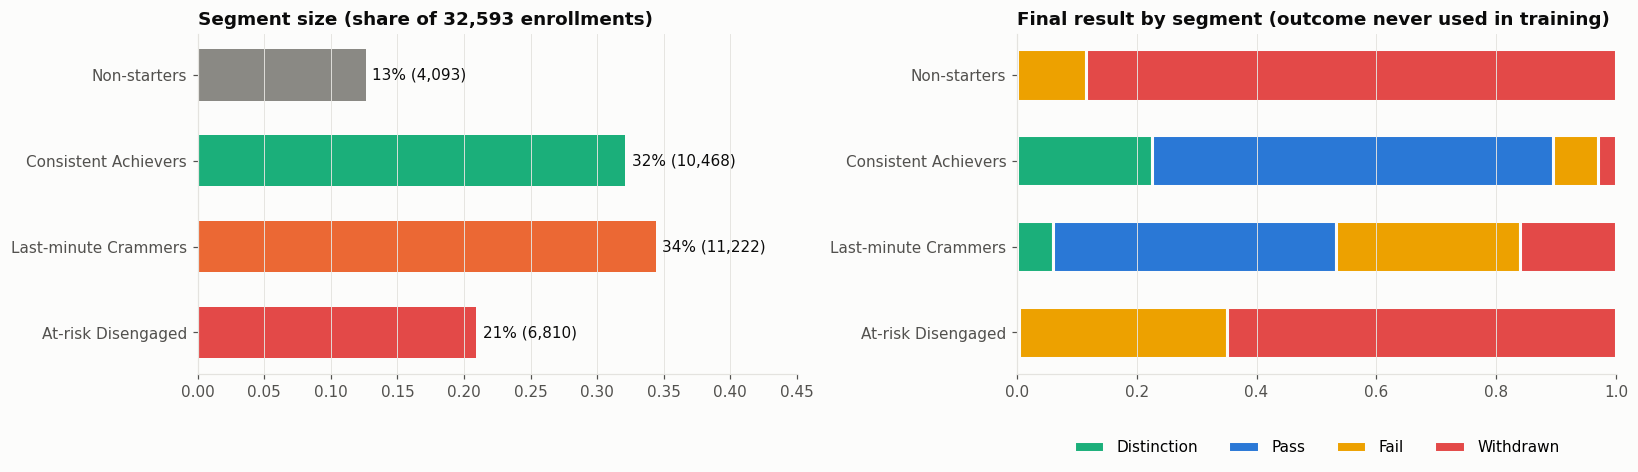

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].barh(PERSONAS[::-1], kpi.share[::-1], color=colors[::-1], height=0.6)
for i, (p, v) in enumerate(zip(PERSONAS[::-1], kpi.share[::-1])):
    ax[0].text(v + 0.005, i, f"{v:.0%} ({kpi.enrollments[p]:,})", va="center", color=V.TEXT)
ax[0].set(title="Segment size (share of 32,593 enrollments)", xlim=(0, 0.45)); ax[0].grid(axis="y", visible=False)
left = np.zeros(len(PERSONAS))
for o in ["Distinction", "Pass", "Fail", "Withdrawn"]:
    v = outcome[o].to_numpy()
    ax[1].barh(PERSONAS, v, left=left, color=V.OUTCOME_COLORS[o], label=o, height=0.6, edgecolor=V.SURFACE, linewidth=2)
    left += v
ax[1].set(title="Final result by segment (outcome never used in training)", xlim=(0, 1)); ax[1].legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.28))
ax[1].invert_yaxis(); ax[1].grid(axis="y", visible=False)
fig.tight_layout(); V.save(fig, "m6_segment_size_outcome"); plt.show()

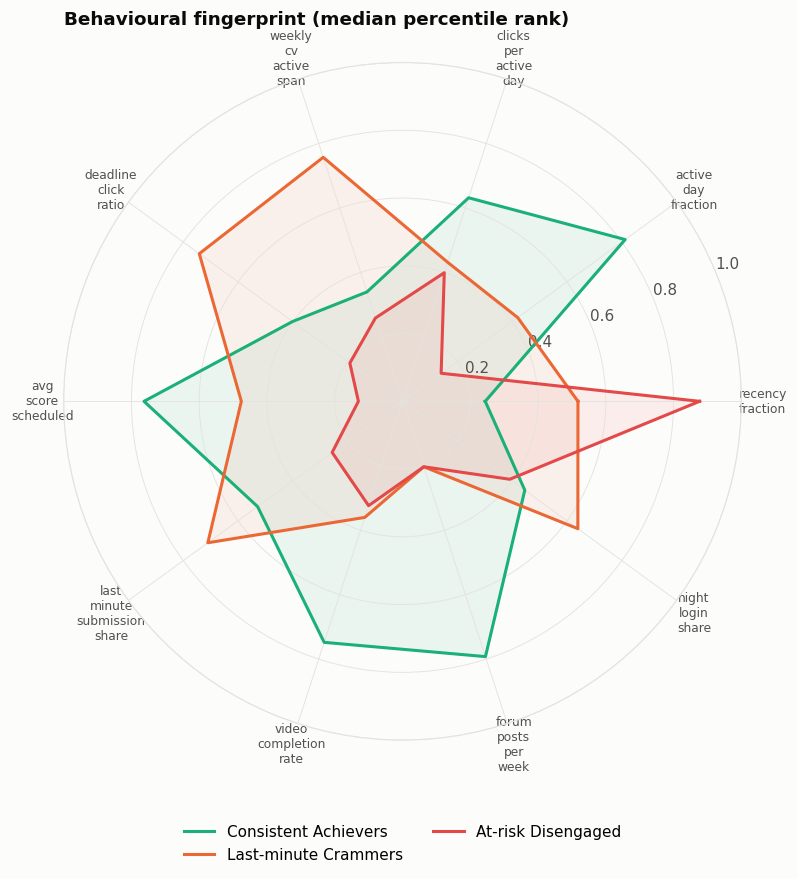

In [5]:
# Radar of percentile ranks (relative to all active learners) for the clustered personas
act = seg[seg.cluster >= 0]
pct = act[SEL].rank(pct=True)
rad = pct.groupby(act.persona).median().reindex([p for p in PERSONAS if p != "Non-starters"])
ang = np.linspace(0, 2 * np.pi, len(SEL), endpoint=False).tolist(); ang += ang[:1]
fig = plt.figure(figsize=(8, 8)); ax = fig.add_subplot(111, polar=True)
for p, row in rad.iterrows():
    v = row.tolist(); v += v[:1]
    ax.plot(ang, v, color=V.PERSONA_COLORS[p], lw=2, label=p); ax.fill(ang, v, color=V.PERSONA_COLORS[p], alpha=0.08)
ax.set_xticks(ang[:-1], [s.replace("_", "\n") for s in SEL], fontsize=8); ax.set_ylim(0, 1)
ax.set_title("Behavioural fingerprint (median percentile rank)", pad=25); ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.2), ncol=2)
V.save(fig, "m6_radar"); plt.show()

### Context mix and fairness check
Demographics were excluded from clustering. We still check whether segments are strongly skewed by protected or
socio-economic attributes, because interventions targeted by segment could then be unequal in effect.

In [6]:
ctx = []
for col in ["course_domain", "age_band", "gender", "disability", "highest_education", "imd_band"]:
    t = pd.crosstab(seg[col], seg.persona, normalize="columns").reindex(columns=PERSONAS)
    t.index = [f"{col} = {i}" for i in t.index]; ctx.append(t)
ctx = pd.concat(ctx).round(3); U.save_table(ctx.reset_index(names="attribute"), "m6_context_mix")
from scipy.stats import chi2_contingency
fair = []
for col in ["gender", "disability", "age_band", "imd_band", "highest_education", "course_domain"]:
    ct = pd.crosstab(seg[col], seg.persona); chi2, p, dof, _ = chi2_contingency(ct)
    fair.append({"attribute": col, "cramers_v": np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))), "p_value": p})
fair = pd.DataFrame(fair).round(4); U.save_table(fair, "m6_fairness_cramers_v"); fair

,attribute,cramers_v,p_value
0,gender,0.0536,0.0
1,disability,0.0596,0.0
2,age_band,0.0961,0.0
3,imd_band,0.0906,0.0
4,highest_education,0.0844,0.0
5,course_domain,0.1135,0.0


Associations between segment and demographics are weak (Cramér's V well below 0.3 — the conventional threshold for
a moderate association). Disadvantage is visible but modest (e.g., lower-education and higher-deprivation learners
are somewhat over-represented among At-risk Disengaged and Non-starters), so support offered *by segment* reaches
disadvantaged learners proportionally without using their protected attributes directly.

## 2. What distinguishes each segment

In [7]:
dist = []
for p in [x for x in PERSONAS if x != "Non-starters"]:
    a, b = act[act.persona == p], act[act.persona != p]
    for f in SEL + ["logins_per_week", "submission_rate"]:
        d = (a[f].mean() - b[f].mean()) / np.sqrt((a[f].var() + b[f].var()) / 2)
        dist.append({"persona": p, "feature": f, "cohens_d_vs_rest": d})
dist = pd.DataFrame(dist)
top = dist.reindex(dist.cohens_d_vs_rest.abs().sort_values(ascending=False).index).groupby("persona").head(5)
U.save_table(dist.round(3), "m6_cohens_d"); top.round(2).sort_values(["persona", "cohens_d_vs_rest"])

,persona,feature,cohens_d_vs_rest
35,At-risk Disengaged,submission_rate,-3.32
29,At-risk Disengaged,avg_score_scheduled,-2.98
25,At-risk Disengaged,active_day_fraction,-1.62
34,At-risk Disengaged,logins_per_week,-1.51
24,At-risk Disengaged,recency_fraction,3.77
0,Consistent Achievers,recency_fraction,-1.47
11,Consistent Achievers,submission_rate,1.52
5,Consistent Achievers,avg_score_scheduled,1.72
10,Consistent Achievers,logins_per_week,1.99
1,Consistent Achievers,active_day_fraction,2.24


In [8]:
cards = {
    "Non-starters": "Registered but never opened the course materials in the course window. 88% withdraw; most never submit anything. The decision point is the first 10 days.",
    "At-risk Disengaged": "Started, then drifted away: active on ~3% of course days, last seen early (median recency 0.84 of the course), submit ~9% of assessments, median score 5/100. 65% withdraw, the rest fail — but they did start, so they can still be reached.",
    "Last-minute Crammers": "Active on ~14% of days, with study concentrated on deadline days (3.4x the uniform rate) and bursty weeks; a quarter of work is submitted in the final 24 h (median lead time under 3 hours) and night logins are more common. They submit most work (89%) and score 58 on average: half pass, a third fail - the most 'movable' group.",
    "Consistent Achievers": "Study on ~40% of course days at an even pace, submit everything with a median 41 h to spare, complete ~76% of videos and post in forums. 90% pass, 22% with distinction.",
}
persona_cards = pd.DataFrame({"segment_id": order.index, "persona": PERSONAS, "description": [cards.get(p, "") for p in PERSONAS],
                              "share": kpi.share.values, "pass_rate": kpi.pass_rate.values, "at_risk_rate": kpi.at_risk_rate.values})
persona_cards

,segment_id,persona,description,share,pass_rate,at_risk_rate
0,S0,Non-starters,Registered but never opened the course materials in the course window. 88% withdraw; most never submit anything. The...,0.126,0.001,0.999
1,S1,Consistent Achievers,"Study on ~40% of course days at an even pace, submit everything with a median 41 h to spare, complete ~76% of videos...",0.321,0.896,0.104
2,S2,Last-minute Crammers,"Active on ~14% of days, with study concentrated on deadline days (3.4x the uniform rate) and bursty weeks; a quarter...",0.344,0.533,0.467
3,S3,At-risk Disengaged,"Started, then drifted away: active on ~3% of course days, last seen early (median recency 0.84 of the course), submi...",0.209,0.003,0.997


## 3. Engagement over time by persona (Lecture 8.1)

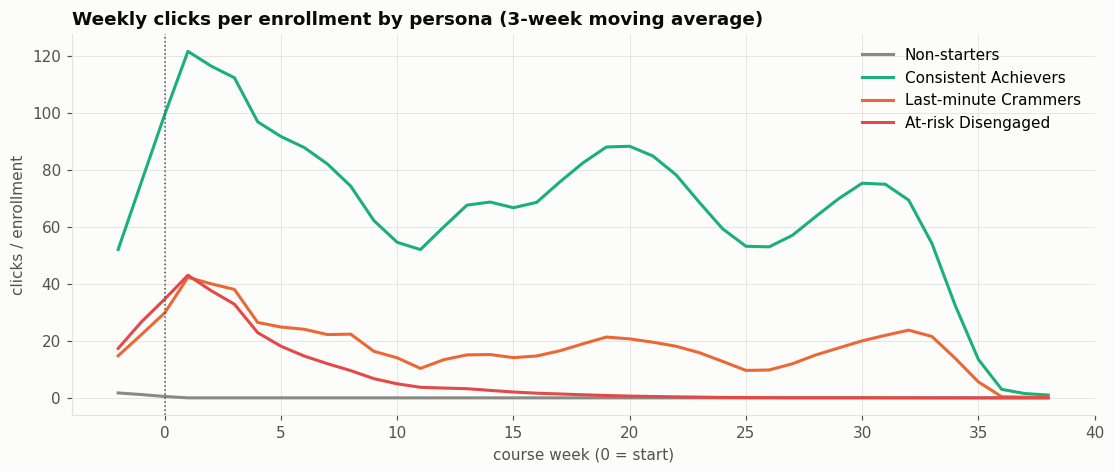

persona
Non-starters              0.0
Consistent Achievers    118.0
Last-minute Crammers     39.3
At-risk Disengaged       39.5
dtype: float64

In [9]:
day = pd.read_parquet(C.INTERIM / "enrollment_day.parquet", columns=C.KEY + ["date", "clicks"])
day = day[day.date.between(-14, 266)].merge(seg[C.KEY + ["persona"]], on=C.KEY)
day["week"] = day.date // 7
wk = day.groupby(["persona", "week"]).clicks.sum().unstack(0).div(seg.persona.value_counts(), axis=1).fillna(0)
fig, ax = plt.subplots(figsize=(12, 4.5))
for p in PERSONAS:
    if p in wk:
        ax.plot(wk.index, wk[p].rolling(3, center=True, min_periods=1).mean(), color=V.PERSONA_COLORS[p], label=p)
ax.axvline(0, color=V.TEXT2, ls=":", lw=1)
ax.set(title="Weekly clicks per enrollment by persona (3-week moving average)", xlabel="course week (0 = start)", ylabel="clicks / enrollment")
ax.legend(); V.save(fig, "m6_weekly_by_persona"); plt.show()
first_month = wk.loc[0:3].mean().reindex(PERSONAS).round(1); first_month

Consistent Achievers are about three times as active as everyone else from **week 0** (~118 vs ~39 clicks per week
in the first month). At-risk Disengaged learners start the course *as active as the Crammers* and then fade within
~10 weeks, while Crammers keep following the assessment calendar with sharp peaks. Month-1 volume alone therefore
separates Achievers and Non-starters, but not yet the two middle personas — which the early-warning model confirms.

## 4. Early warning: predicting the segment from the first 28 days (Lecture 10 — classification)
The segmentation itself is retrospective (it uses the whole course). For intervention we need the segment *early*.
We train a classifier whose inputs are only facts known on **day 28**, and whose label is the final segment.

In [10]:
d28 = pd.read_parquet(C.INTERIM / "enrollment_day.parquet")
d28 = d28[d28.date.between(-30, 27)]
e = d28[d28.date >= 0].groupby(C.KEY).agg(early_clicks=("clicks", "sum"), early_active_days=("date", "nunique"),
                                          early_forum=("forum_clicks", "sum"), early_last_day=("date", "max")).reset_index()
pre = d28[d28.date < 0].groupby(C.KEY).clicks.sum().rename("pre_course_clicks_28").reset_index()
sa = pd.read_csv(C.RAW / "studentAssessment.csv", na_values="?").merge(pd.read_csv(C.RAW / "assessments.csv", na_values="?"), on="id_assessment")
sa = sa[(sa.date <= 28) & (sa.assessment_type != "Exam") & (sa.date_submitted <= 28)]
first_ass = sa.groupby(C.KEY).agg(early_submissions=("id_assessment", "nunique"), early_score=("score", "mean")).reset_index()
sess = pd.read_parquet(C.INTERIM / "sessions_clean.parquet", columns=C.KEY + ["course_day", "login_hour", "videos_started", "videos_completed"])
sess = sess[sess.course_day.between(0, 27)]
es = sess.groupby(C.KEY).agg(early_logins=("course_day", "size"), early_videos_started=("videos_started", "sum"),
                             early_videos_completed=("videos_completed", "sum"),
                             early_night=("login_hour", lambda h: h.isin([22, 23, 0, 1, 2, 3, 4, 5]).mean())).reset_index()
ew = seg[C.KEY + ["segment_id", "persona", "split", "date_registration", "num_of_prev_attempts", "studied_credits"]]
for t_ in [e, pre, first_ass, es]:
    ew = ew.merge(t_, on=C.KEY, how="left")
ew = ew.fillna({c: 0 for c in ["early_clicks", "early_active_days", "early_forum", "pre_course_clicks_28", "early_submissions",
                               "early_logins", "early_videos_started", "early_videos_completed", "early_night"]})
ew["early_recency"] = 27 - ew.early_last_day.fillna(-1)
ew["early_score"] = ew.early_score.fillna(-1)               # -1 = no early marked assessment
ew["early_video_rate"] = ew.early_videos_completed / ew.early_videos_started.replace(0, np.nan)
ew["early_video_rate"] = ew.early_video_rate.fillna(0)
XCOLS = ["early_clicks", "early_active_days", "early_forum", "pre_course_clicks_28", "early_submissions", "early_score",
         "early_logins", "early_video_rate", "early_night", "early_recency", "date_registration", "num_of_prev_attempts", "studied_credits"]
ew["date_registration"] = ew.date_registration.fillna(ew.date_registration.median())
tr_, te_ = ew[ew.split == "train"], ew[ew.split == "monitor"]
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight="balanced", random_state=C.SEED, n_jobs=-1)
rf.fit(tr_[XCOLS], tr_.persona)
pred = rf.predict(te_[XCOLS])
ew_bacc = balanced_accuracy_score(te_.persona, pred)
rep = pd.DataFrame(classification_report(te_.persona, pred, output_dict=True)).T.round(3)
U.save_table(rep.reset_index(names="class"), "m6_early_warning_report")
print(f"Early-warning model (day 28) on the unseen 2014J cohort — balanced accuracy {ew_bacc:.3f}")
rep

Early-warning model (day 28) on the unseen 2014J cohort — balanced accuracy 0.735


,precision,recall,f1-score,support
At-risk Disengaged,0.545,0.549,0.547,2295.000
Consistent Achievers,0.740,0.769,0.754,3296.000
Last-minute Crammers,0.672,0.624,0.647,4239.000
Non-starters,0.902,0.999,0.948,1430.000
accuracy,0.699,0.699,0.699,0.699
macro avg,0.715,0.735,0.724,11260.000
weighted avg,0.695,0.699,0.696,11260.000


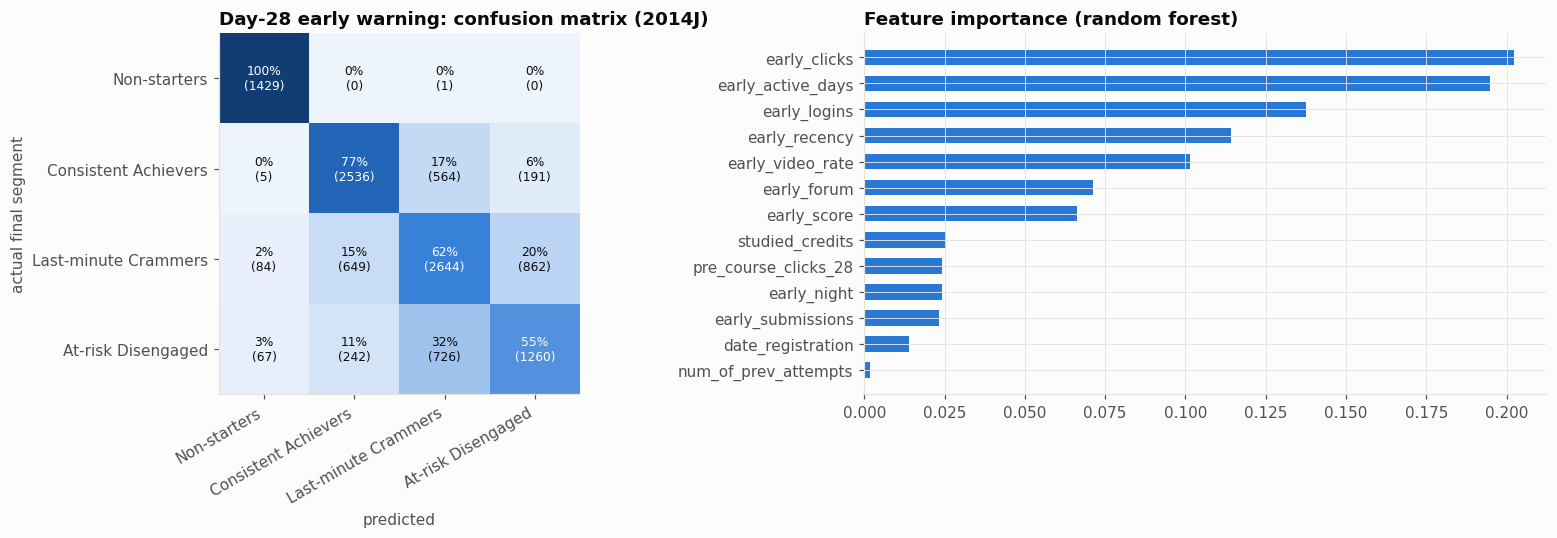

['E:\\20261\\BA\\midterm-project\\models\\early_warning_rf.joblib']

In [11]:
cm = pd.DataFrame(confusion_matrix(te_.persona, pred, labels=PERSONAS), index=PERSONAS, columns=PERSONAS)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
cmn = cm.div(cm.sum(1), axis=0)
im = ax[0].imshow(cmn, cmap=V.SEQUENTIAL, vmin=0, vmax=1)
ax[0].set_xticks(range(len(PERSONAS)), PERSONAS, rotation=30, ha="right"); ax[0].set_yticks(range(len(PERSONAS)), PERSONAS)
for i in range(len(PERSONAS)):
    for j in range(len(PERSONAS)):
        ax[0].text(j, i, f"{cmn.iloc[i, j]:.0%}\n({cm.iloc[i, j]})", ha="center", va="center", fontsize=8,
                   color="white" if cmn.iloc[i, j] > 0.5 else V.TEXT)
ax[0].grid(False); ax[0].set(title="Day-28 early warning: confusion matrix (2014J)", xlabel="predicted", ylabel="actual final segment")
imp = pd.Series(rf.feature_importances_, index=XCOLS).sort_values()
ax[1].barh(imp.index, imp.values, color=V.CATEGORICAL[0], height=0.6); ax[1].set(title="Feature importance (random forest)")
fig.tight_layout(); V.save(fig, "m6_early_warning"); plt.show()
joblib.dump({"model": rf, "features": XCOLS}, C.MODELS / "early_warning_rf.joblib")

By day 28 the final segment is predictable well above chance (balanced accuracy ≈ 0.74 vs 0.25 for 4 classes),
on a cohort the model never saw. **Non-starters are found almost perfectly** (recall ≈ 1.0) and Consistent Achievers
well (≈ 0.77). Future **At-risk Disengaged** learners are the hardest (recall ≈ 0.55): in month 1 many still look
like Crammers — the difference appears when they stop coming back. Practical use: flag Non-starters on day 10–28
with near certainty, and treat "predicted At-risk or Crammer with low early score" as a watch list re-scored weekly.
The model is a decision aid; tutors confirm before acting.

## 5. Recommendations per persona (content · pacing · support)

In [12]:
recs = pd.DataFrame([{"persona": p, **B.RECOMMENDATIONS[p]} for p in PERSONAS])
U.save_table(recs, "m6_recommendations"); recs

,persona,content,pacing,support,kpi,intervention
0,Non-starters,Short 'first 15 minutes' onboarding module and a visible week-1 checklist.,Soft-start deadline: first activity expected within 7 days of course start.,"Automated welcome sequence on day 1, 3 and 7; tutor call if still inactive on day 10; offer deferral.",Share starting within 14 days; withdrawal before day 30.,automated_nudges
1,Consistent Achievers,"Advanced / extension content, recognition badges, pathways to next module.",Standard or accelerated pacing.,Recruit as peer mentors / forum moderators; minimal tutor time needed.,"Distinction rate, progression to next module.",peer_study_group
2,Last-minute Crammers,Break assessments into checkpoints; release practice quizzes 7-10 days before each deadline.,Interim mini-deadlines and calendar nudges 5 and 2 days before deadlines (not at night).,Study-plan coaching session on time management; peer accountability pairs.,"Last-minute submission share, deadline click ratio.",study_plan_coaching
3,At-risk Disengaged,Condensed 'catch-up path' covering assessed outcomes only; mobile-friendly micro lessons.,Re-planned personal schedule with one achievable milestone per week; extension policy explained.,Proactive tutor outreach call when recency > 14 days; refer to student-support services.,"Recency < 7 days, next assessment submitted.",tutor_outreach_call


## 6. Decision analysis: is intervening worth it? (Lecture 2)
For one learner in segment *s* with baseline pass probability p₀ and intervention *i* (cost c, assumed uplift u):

EV(no action) = p₀·V  EV(intervene) = (p₀ + u)·V − c  with V = USD 400 per additional pass.
Sunk costs (e.g., platform licences) are ignored, as the lecture prescribes. Break-even uplift = c / V.

In [13]:
segk = kpi.reset_index(names="persona")[["persona", "pass_rate"]]
ev = B.decision_tree_ev(segk)
U.save_table(ev.round(3), "m6_decision_ev"); ev.round(3)

,persona,intervention,pass_rate,uplift,cost,ev_no_action,ev_intervene,net_gain_per_learner,break_even_uplift
0,Non-starters,tutor_outreach_call,0.001,0.120,35.0,0.4,13.4,13.0,0.088
1,Consistent Achievers,automated_nudges,0.896,0.004,2.0,358.4,358.0,-0.4,0.005
2,Last-minute Crammers,study_plan_coaching,0.533,0.096,15.0,213.2,236.6,23.4,0.038
3,At-risk Disengaged,tutor_outreach_call,0.003,0.150,35.0,1.2,26.2,25.0,0.088


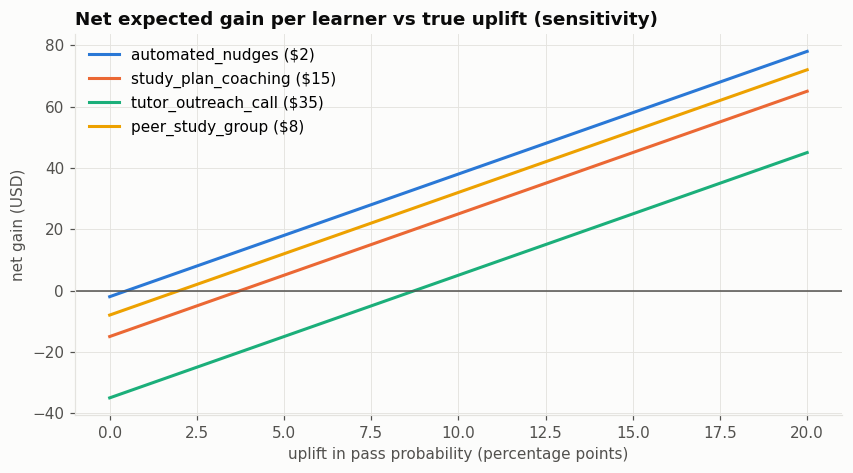

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.5))
uplift = np.linspace(0, 0.2, 41)
for name, (cost, _, _) in C.INTERVENTION_CATALOGUE.items():
    ax.plot(uplift * 100, uplift * C.VALUE_OF_RETAINED_LEARNER - cost, label=f"{name} (${cost:.0f})")
ax.axhline(0, color=V.TEXT2, lw=1)
ax.set(title="Net expected gain per learner vs true uplift (sensitivity)", xlabel="uplift in pass probability (percentage points)", ylabel="net gain (USD)")
ax.legend(); V.save(fig, "m6_ev_sensitivity"); plt.show()

Every intervention is worth it only above its break-even uplift (0.5 pp for nudges, 8.75 pp for a tutor call). The
segment fit matters more than the instrument: an expensive tutor call is justified for Non-starters / At-risk
Disengaged (large room to improve), but has negative expected value for Consistent Achievers, who pass anyway.

## 7. Optimal allocation of a support budget (Lecture 3.2 — linear programming)
**Decision variables** x(s, i) = learners of segment s receiving intervention i.
**Objective** maximise expected additional passes Σ x(s,i)·u(s,i).
**Constraints** Σ x·cost ≤ budget; Σ x·tutor minutes ≤ tutor capacity; Σᵢ x(s,i) ≤ size of segment s; x ≥ 0.
Planning case: the incoming 2014J cohort (11,260 enrollments), budget USD 60,000, 600 tutor hours.

In [15]:
cohort = seg[seg.split == "monitor"].persona.value_counts().to_dict()
opt = B.optimise_allocation(cohort, budget=60_000, tutor_hours=600)
alloc = opt["allocation"][["persona", "intervention", "learners_allocated", "uplift", "cost", "spend", "expected_extra_passes"]]
U.save_table(alloc.round(2), "m6_lp_allocation")
print(opt["status"]); print(f"expected extra passes: {opt['expected_extra_passes']:.0f} | spend ${opt['spend']:,.0f} | tutor hours {opt['tutor_hours_used']:.0f}")
print("shadow prices:", {k: v for k, v in opt["shadow_prices"].items() if abs(v) > 1e-6})
alloc.round(2)

Optimization terminated successfully. (HiGHS Status 7: Optimal)
expected extra passes: 297 | spend $39,328 | tutor hours 600
shadow prices: {'tutor_minutes': np.float64(0.0036), 'capacity:Last-minute Crammers': np.float64(0.024), 'capacity:At-risk Disengaged': np.float64(0.016), 'capacity:Non-starters': np.float64(0.02)}


,persona,intervention,learners_allocated,uplift,cost,spend,expected_extra_passes
0,Last-minute Crammers,automated_nudges,2439.0,0.02,2.0,4878.0,58.54
1,Last-minute Crammers,study_plan_coaching,1800.0,0.10,15.0,27000.0,172.80
4,At-risk Disengaged,automated_nudges,2295.0,0.02,2.0,4590.0,36.72
8,Non-starters,automated_nudges,1430.0,0.02,2.0,2860.0,28.60


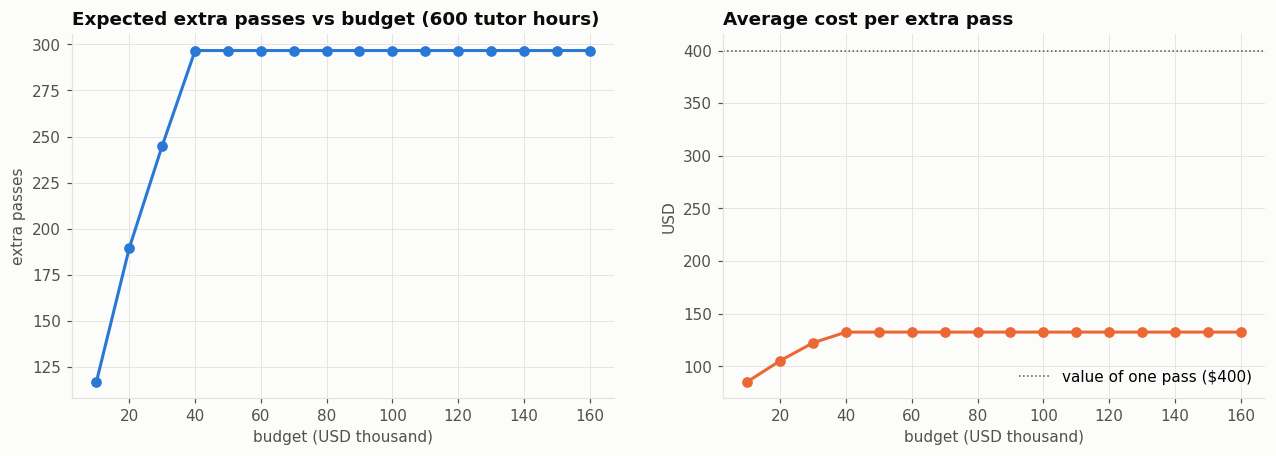

,budget,expected_extra_passes,spend,cost_per_extra_pass
0,10000,116.96,10000.0,85.50
1,20000,189.61,19999.6,105.48
2,30000,244.99,30000.5,122.45
3,40000,296.66,39328.0,132.57
4,50000,296.66,39328.0,132.57
5,60000,296.66,39328.0,132.57
6,70000,296.66,39328.0,132.57
7,80000,296.66,39328.0,132.57
8,90000,296.66,39328.0,132.57
9,100000,296.66,39328.0,132.57


In [16]:
budgets = np.arange(10_000, 160_001, 10_000)
curve = pd.DataFrame([{"budget": b_, **{k: v for k, v in B.optimise_allocation(cohort, b_, 600).items() if k in ("expected_extra_passes", "spend")}} for b_ in budgets])
curve["cost_per_extra_pass"] = curve.spend / curve.expected_extra_passes
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
ax[0].plot(curve.budget / 1000, curve.expected_extra_passes, marker="o")
ax[0].set(title="Expected extra passes vs budget (600 tutor hours)", xlabel="budget (USD thousand)", ylabel="extra passes")
ax[1].plot(curve.budget / 1000, curve.cost_per_extra_pass, marker="o", color=V.CATEGORICAL[1])
ax[1].axhline(C.VALUE_OF_RETAINED_LEARNER, color=V.TEXT2, ls=":", lw=1, label="value of one pass ($400)")
ax[1].set(title="Average cost per extra pass", xlabel="budget (USD thousand)", ylabel="USD"); ax[1].legend()
V.save(fig, "m6_lp_sensitivity"); plt.show()
U.save_table(curve.round(2), "m6_lp_budget_curve")

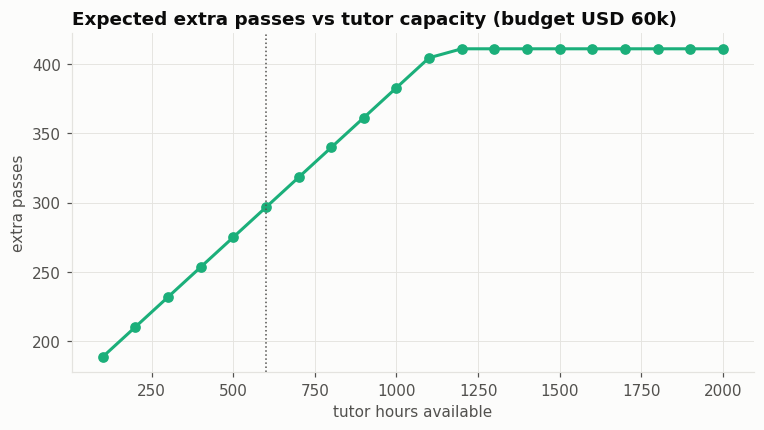

Shadow price of a tutor hour: 0.216 extra passes = USD 86 of value; shadow price of budget: 0.0000


In [17]:
# Sensitivity on the binding resource: tutor capacity (budget fixed at USD 60,000)
hours = np.arange(100, 2001, 100)
hcurve = pd.DataFrame([{"tutor_hours": h, **{k: v for k, v in B.optimise_allocation(cohort, 60_000, h).items() if k in ("expected_extra_passes", "spend")}} for h in hours])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hcurve.tutor_hours, hcurve.expected_extra_passes, marker="o", color=V.CATEGORICAL[2])
ax.axvline(600, color=V.TEXT2, ls=":", lw=1)
ax.set(title="Expected extra passes vs tutor capacity (budget USD 60k)", xlabel="tutor hours available", ylabel="extra passes")
V.save(fig, "m6_lp_tutor_hours"); plt.show()
U.save_table(hcurve.round(2), "m6_lp_tutor_curve")
sp = opt["shadow_prices"]
print(f"Shadow price of a tutor hour: {60 * sp['tutor_minutes']:.3f} extra passes "
      f"= USD {60 * sp['tutor_minutes'] * C.VALUE_OF_RETAINED_LEARNER:.0f} of value; shadow price of budget: {sp['budget']:.4f}")

**Reading the LP.** With 600 tutor hours the *tutor capacity is the binding constraint*, not money: about USD 39k of
the USD 60k budget is enough, and extra budget adds nothing (budget shadow price = 0). One more tutor hour is worth
≈ 0.22 additional passes (≈ USD 86 of value), so the platform should buy tutor time at up to ~USD 86/hour before
raising the cash budget. The optimal plan gives scarce tutor time to **study-plan coaching for Last-minute
Crammers** (largest uplift per tutor minute) and cheap automated nudges to the other at-risk segments; it spends
nothing on Consistent Achievers.

In [18]:
# Benchmark: segment-blind policy (tutor call to random learners until budget or capacity runs out)
n_blind = min(60_000 / 35, 600 * 60 / 45)
um = B.segment_uplift_matrix(list(cohort))
avg_u = sum(cohort[p] * um[(um.persona == p) & (um.intervention == "tutor_outreach_call")].uplift.iloc[0] for p in cohort) / sum(cohort.values())
blind = {"learners": n_blind, "extra_passes": n_blind * avg_u, "spend": n_blind * 35}
blind["cost_per_extra_pass"] = blind["spend"] / blind["extra_passes"]
kpi_cmp = pd.DataFrame([{"policy": "segment-blind tutor calls", **blind},
                        {"policy": "segment-targeted LP", "learners": float(alloc.learners_allocated.sum()),
                         "extra_passes": opt["expected_extra_passes"], "spend": opt["spend"],
                         "cost_per_extra_pass": opt["spend"] / opt["expected_extra_passes"]}]).round(1)
U.save_table(kpi_cmp, "m6_policy_comparison"); kpi_cmp

,policy,learners,extra_passes,spend,cost_per_extra_pass
0,segment-blind tutor calls,800.0,66.1,28000.0,423.6
1,segment-targeted LP,7964.0,296.7,39328.0,132.6


Under the same budget and tutor capacity, targeting by segment reaches far more learners (cheap nudges where they
suffice, scarce tutor time where it has the largest effect per minute) and cuts the **cost per additional pass** —
the intervention-cost KPI defined in Module 1 — to well below the USD 400 value of a pass, whereas segment-blind
tutor calls cost more than a pass is worth. Options whose expected value is below their cost (e.g., any paid support
for Consistent Achievers) are excluded from the LP. The shadow prices show which constraint binds: an extra tutor hour or
extra dollar is worth the reported number of additional passes, guiding whether to buy tutor time or budget first.
All uplifts are assumptions; the recommended next step is an A/B test per segment to replace them with estimates.

In [19]:
personas_json = {
    "segments": [{"segment_id": sid, "name": p, "color": V.PERSONA_COLORS[p], "description": cards.get(p, ""),
                  "kpis": {k: (float(v) if not isinstance(v, str) else v) for k, v in kpi.loc[p].items()},
                  "profile_medians": {f: float(prof.loc[f, p]) for f in prof.index},
                  "recommendations": B.RECOMMENDATIONS[p]} for sid, p in order.items()],
    "features": SEL,
}
(C.MODELS / "personas.json").write_text(json.dumps(personas_json, indent=2))
U.save_metrics("m6", {"kpi": kpi.reset_index(names="persona").to_dict("records"), "fairness": fair.to_dict("records"),
                      "early_warning_balanced_accuracy": ew_bacc, "early_warning_report": rep.reset_index(names="class").to_dict("records"),
                      "decision_ev": ev.round(3).to_dict("records"), "lp": {k: v for k, v in opt.items() if k != "allocation"},
                      "lp_allocation": alloc.round(2).to_dict("records"), "policy_comparison": kpi_cmp.to_dict("records"),
                      "first_month_clicks": first_month.to_dict(), "cohort_2014J": cohort})